# Negocio: de los datos a la recomendación municipal

Este notebook explica, paso a paso, cómo se transforma la Gold municipal en una recomendación de aperturas para un gimnasio low-cost.

Se comparan tres estrategias:

1. **Baseline**: los cinco municipios con mayor población de 18 a 50 años.
2. **Modelo**: municipios con menor competencia relativa que la media de su cluster, viables y que superan el control de calidad.
3. **Modelo diversificado por clusters**: alternativa que intenta representar distintos perfiles municipales, sin introducir municipios no viables o con calidad insuficiente.

El notebook **no redefine las fórmulas**. Utiliza las funciones de `src/negocio/valor_negocio.py`. Las cifras son estimaciones bajo supuestos centrales, no ingresos observados.

La ejecución automática, que genera los CSV y `tablas_definitivas_negocio.md`, sigue siendo:

```powershell
python -m src.negocio.ejecutar
```

## 0. Configuración

Se localiza la raíz del repositorio y se importan los módulos oficiales. El notebook se puede abrir desde la raíz o desde `notebooks/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

working_directory = Path.cwd().resolve()
project_root = next(
    (
        path for path in (working_directory, *working_directory.parents)
        if (path / "src" / "negocio" / "ejecutar.py").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("No se encontró la raíz con src/negocio/ejecutar.py")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.negocio import ejecutar, valor_negocio
from src.modelo.modelo import guardar_municipios_candidatos
from src.negocio.supuestos import ESCENARIOS_PESOS, PESOS_CENTRAL, SUPUESTOS, parametros
from src.procesado.common.paths import GOLD_TABLE_PATH

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print(f"Raíz del proyecto: {project_root}")

Raíz del proyecto: C:\Users\d.gonzalez.fuentes\OneDrive - Accenture\Documents\market-expansion-sot-main


## 1. Carga y validación de entradas

Se leen la Gold y las asignaciones de clusters mediante la función oficial `ejecutar.cargar()`.

Comprobaciones principales:

- Municipios que superaron los filtros de datos del modelo (cantidad variable).
- Un código municipal único de cinco dígitos.
- Un cluster informado para cada municipio incluido.
- Recuentos de competencia disponibles.

In [2]:
datos = ejecutar.cargar()

assert datos["municipality_code"].is_unique
assert datos["municipality_code"].astype("string").str.fullmatch(r"\d{5}").all()
assert datos["cluster"].notna().all()

print(f"Gold + clusters: {len(datos)} municipios")
print(f"Origen Gold: {GOLD_TABLE_PATH}")
display(
    datos[[
        "municipality_code", "municipality_name", "province",
        "population_18_50", "gyms_count",
        "other_sports_facilities_count", "cluster",
    ]].head(8)
)
display(
    datos.groupby("cluster").size().rename("municipios").to_frame()
)

Clusters leídos de clusters.parquet: 4 grupos
Entrada: Gold 783 municipios; 783 incluidos tras filtros del modelo; clusters: sí
Gold + clusters: 783 municipios
Origen Gold: C:\Users\d.gonzalez.fuentes\OneDrive - Accenture\Documents\market-expansion-sot-main\data\processed\gold\tabla_oro_municipios_andalucia.parquet


,municipality_code,municipality_name,province,population_18_50,gyms_count,other_sports_facilities_count,cluster
0,04001,Abla,Almería,464,0,1,1
1,04002,Abrucena,Almería,442,0,0,1
2,04003,Adra,Almería,11849,6,9,2
3,04004,Albanchez,Almería,174,0,0,1
4,04005,Alboloduy,Almería,216,0,0,1
5,04006,Albox,Almería,5392,3,12,2
6,04007,Alcolea,Almería,285,0,1,1
7,04008,Alcóntar,Almería,178,0,0,1


,municipios
cluster,
0,96
1,204
2,362
3,121


## 2. Supuestos del escenario central

El cálculo utiliza los valores definidos en `supuestos.py`. Las referencias completas se mantienen en la documentación del proyecto.

### Referencia económica del centro

- **Costes operativos anuales considerados:** 556.000 €.
- **Ticket mensual sin IVA:** 22,37 €.
- **Capacidad de referencia:** 2.600 socios.
- **Punto de equilibrio aproximado:** 2.071 socios.

Con 2.600 socios, la facturación operativa de referencia sería:

```text
2.600 socios × 22,37 €/mes × 12 meses = 697.944 €/año
```

La capacidad de 2.600 socios **no es la capacidad óptima calculada para cada municipio**. Es un formato estándar que permite comparar todos los municipios con el mismo criterio. Cuando la demanda captable supera ampliamente este valor, el resultado indica que merece la pena estudiar un centro mayor, varias aperturas o una configuración distinta de costes.

In [3]:
p = parametros("central")
claves = [
    "penetracion", "ticket_mensual", "capacidad", "cuota_max",
    "atractivo_nuevo", "coste_anual_club",
]
filas = []
for clave in claves:
    info = SUPUESTOS.get(clave, {})
    filas.append({
        "Supuesto": clave,
        "Valor central": p[clave],
        "Fuente / criterio": info.get("fuente", "Ver documentación"),
    })
display(pd.DataFrame(filas))

display(pd.DataFrame([
    {"Tipo de instalación": tipo, "Peso": peso}
    for tipo, peso in ESCENARIOS_PESOS[PESOS_CENTRAL].items()
]))

facturacion_operativa_maxima = p["capacidad"] * p["ticket_mensual"] * 12
print(f"Facturación operativa máxima del centro estándar: {facturacion_operativa_maxima:,.0f} € / año")

,Supuesto,Valor central,Fuente / criterio
0,penetracion,0.22,Bajo: Informe anual sector fitness España 2025...
1,ticket_mensual,22.37,Bajo: Planet Fitness Clásico 18 €/mes con IVA....
2,capacidad,"2,600.00",Socios por centro de los 4 grandes low-cost en...
3,cuota_max,0.40,Supuesto del equipo. Sin fuente directa; se pr...
4,atractivo_nuevo,2.18,Socios por centro low-cost en España (GestiónF...
5,coste_anual_club,"556,000.00",Basic-Fit FY2025: costes de club (personal 261...


,Tipo de instalación,Peso
0,fitness_centre,1.00
1,sports_centre,0.10
2,fitness_station,0.10


Facturación operativa máxima del centro estándar: 697,944 € / año


## 3. Competencia ponderada

No todas las instalaciones deportivas compiten igual con un gimnasio low-cost. Por eso se convierten en **equivalentes de gimnasio**:

```text
Competencia ponderada = gimnasios + 0,1 × otras instalaciones deportivas
```

Después se ajusta el resultado al tamaño del mercado objetivo:

```text
Competencia por 10.000 = competencia ponderada / población de 18 a 50 × 10.000
```

Así, diez competidores no se interpretan igual en un municipio pequeño que en una gran ciudad.

In [4]:
competencia = valor_negocio.competidores_ponderados(datos, pesos=PESOS_CENTRAL)

muestra_nombres = [
    "Sevilla", "Málaga", "Marbella", "Algeciras",
    "Huelva", "Fuengirola", "Puerto de Santa María, El",
]
muestra_competencia = competencia.loc[
    competencia["municipality_name"].isin(muestra_nombres),
    [
        "municipality_name", "population_18_50", "gyms_count",
        "other_sports_facilities_count", "competidores_pond",
        "comp_per_10k_18_50",
    ],
].sort_values("population_18_50", ascending=False)
display(muestra_competencia)

,municipality_name,population_18_50,gyms_count,other_sports_facilities_count,competidores_pond,comp_per_10k_18_50
767,Sevilla,291636,45,179,62.90,2.16
640,Málaga,262785,47,129,59.90,2.28
642,Marbella,72448,2,39,5.90,0.81
437,Huelva,60725,5,26,7.60,1.25
105,Algeciras,55729,5,22,7.20,1.29
128,"Puerto de Santa María, El",38048,0,12,1.20,0.32
627,Fuengirola,34640,1,21,3.10,0.89


## 4. Control de calidad de la competencia

Este control responde a una pregunta concreta:

> **¿La competencia registrada parece suficientemente completa para confiar en el posible hueco de mercado?**

Se utiliza como referencia **1 equivalente de gimnasio por cada 10.000 habitantes de 18 a 50 años**:

```text
Gimnasios equivalentes esperados = población de 18 a 50 / 10.000
```

Después se compara la competencia ponderada observada con esa referencia:

```text
Cobertura ponderada (%) = competencia ponderada / gimnasios esperados × 100
```

Interpretación:

- **`quality_flag=True`**: la cobertura es igual o superior al 50 % y supera el control mínimo.
- **`quality_flag=False`**: la cobertura es inferior al 50 %; el municipio no se elimina, pero debe validarse con una segunda fuente.
- **Más del 100 %**: es posible. Indica que la oferta ponderada observada supera la referencia. No demuestra por sí sola sobresaturación ni un error.

Este control evalúa la **confianza en el dato**, no si el municipio es una oportunidad.

In [5]:
columnas_calidad = [
    "municipality_name", "competidores_pond", "expected_gyms",
    "weighted_observed_vs_expected_pct", "quality_flag", "quality_status",
]
display(
    competencia.loc[
        competencia["municipality_name"].isin(muestra_nombres),
        columnas_calidad,
    ].sort_values("weighted_observed_vs_expected_pct", ascending=False)
)

print("Distribución del control de calidad:")
display(
    competencia["quality_flag"].value_counts(dropna=False)
    .rename_axis("quality_flag").rename("municipios").to_frame()
)

,municipality_name,competidores_pond,expected_gyms,weighted_observed_vs_expected_pct,quality_flag,quality_status
640,Málaga,59.90,26.28,227.94,True,Supera el control de calidad de competencia po...
767,Sevilla,62.90,29.16,215.68,True,Supera el control de calidad de competencia po...
105,Algeciras,7.20,5.57,129.20,True,Supera el control de calidad de competencia po...
437,Huelva,7.60,6.07,125.15,True,Supera el control de calidad de competencia po...
627,Fuengirola,3.10,3.46,89.49,True,Supera el control de calidad de competencia po...
642,Marbella,5.90,7.24,81.44,True,Supera el control de calidad de competencia po...
128,"Puerto de Santa María, El",1.20,3.80,31.54,False,Competencia ponderada inferior al 50% de la re...


Distribución del control de calidad:


,municipios
quality_flag,
True,580
False,203


## 5. Candidatos: hueco relativo dentro del cluster

Este paso responde a una pregunta distinta:

> **¿Tiene el municipio menos competencia que otros municipios con un perfil parecido?**

```text
Candidato = competencia por 10.000 del municipio
            < media de competencia por 10.000 de su cluster
```

Por tanto:

- `quality_flag` indica si la cobertura de competencia parece suficientemente fiable.
- `candidate_flag` indica si existe un posible hueco relativo frente a municipios comparables.

Para entrar en la recomendación final, un municipio debe ser **candidato, viable y superar el control de calidad**.

In [6]:
candidatos = valor_negocio.candidatos(competencia)

candidatos_publicados = guardar_municipios_candidatos(
    candidatos.loc[
        candidatos["candidate_flag"],
        ["municipality_code", "cluster"],
    ]
)
print(f"Candidatos publicados para Streamlit: {len(candidatos_publicados)}")

resumen_candidatos = candidatos.groupby("cluster").agg(
    municipios=("municipality_code", "size"),
    candidatos=("candidate_flag", "sum"),
    media_competencia=("media_cluster_comp_per_10k", "first"),
).reset_index()
display(resumen_candidatos)

display(
    candidatos[[
        "municipality_name", "cluster", "comp_per_10k_18_50",
        "media_cluster_comp_per_10k", "candidate_flag", "quality_flag",
    ]].head(10)
)

Candidatos publicados para Streamlit: 564


,cluster,municipios,candidatos,media_competencia
0,0,96,69,4.01
1,1,204,157,7.83
2,2,362,255,3.16
3,3,121,83,2.46


,municipality_name,cluster,comp_per_10k_18_50,media_cluster_comp_per_10k,candidate_flag,quality_flag
0,Abla,1,2.16,7.83,True,True
1,Abrucena,1,0.00,7.83,True,False
2,Adra,2,5.82,3.16,False,True
3,Albanchez,1,0.00,7.83,True,False
4,Alboloduy,1,0.00,7.83,True,False
5,Albox,2,7.79,3.16,False,True
6,Alcolea,1,3.51,7.83,True,True
7,Alcóntar,1,0.00,7.83,True,False
8,Alcudia de Monteagud,1,0.00,7.83,True,False
9,Alhabia,0,32.93,4.01,False,True


## 6. Demanda potencial

Primero se estima cuántas personas del público objetivo podrían estar interesadas en un gimnasio:

```text
Socios potenciales = población de 18 a 50 × tasa de penetración
```

Después se relaciona el mercado potencial con la competencia existente:

```text
Demanda por competidor = socios potenciales / máximo(competencia ponderada, 1)
```

Esta métrica sirve para comparar municipios. No representa altas observadas ni garantiza que todas esas personas se conviertan en clientes.

In [7]:
demanda = valor_negocio.demanda(candidatos, p)
display(
    demanda[[
        "municipality_name", "population_18_50", "socios_potenciales",
        "mercado_potencial_eur", "demanda_por_comp",
    ]].sort_values("demanda_por_comp", ascending=False).head(10)
)

,municipality_name,population_18_50,socios_potenciales,mercado_potencial_eur,demanda_por_comp
680,Alcalá de Guadaíra,34632,"7,549.78","2,026,661.87","7,549.78"
128,"Puerto de Santa María, El",38048,"8,294.46","2,226,565.92","6,912.05"
527,Linares,22311,"4,863.80","1,305,637.94","4,863.80"
184,Lucena,19171,"4,179.28","1,121,885.39","4,179.28"
745,"Palacios y Villafranca, Los",17471,"3,808.68","1,022,401.52","3,808.68"
440,Lepe,14511,"3,163.40","849,182.56","3,163.40"
710,Coria del Río,13893,"3,028.67","813,017.25","3,028.67"
580,Alhaurín de la Torre,20090,"4,379.62","1,175,665.19","2,919.75"
715,Écija,16922,"3,689.00","990,274.09","2,837.69"
697,Camas,12989,"2,831.60","760,115.24","2,831.60"


## 7. Captación y facturación

### ¿Qué significa la cuota del centro?

La **cuota del centro** es la parte del mercado potencial que estimamos que podría captar el nuevo gimnasio.

La estimación combina:

- **Atractivo del nuevo centro (`f`)**: ventaja competitiva esperada del formato low-cost.
- **Competencia ponderada**: cuanta más competencia existe, menor cuota puede captar el nuevo centro.
- **Cuota máxima**: límite prudente para evitar asumir que un único gimnasio captará una proporción poco realista del mercado.

```text
Cuota estimada = mínimo(
    atractivo / (competencia ponderada + atractivo),
    cuota máxima
)
```

Ejemplo conceptual: si aumenta la competencia, el denominador crece y la cuota estimada baja. Si hay poca competencia, la cuota aumenta, pero nunca supera el 40 % fijado en el escenario central.

A partir de esa cuota:

```text
Socios captables = socios potenciales × cuota estimada
```

```text
Facturación anual sin tope = socios captables × ticket mensual × 12
```

La **facturación anual sin tope** permite comparar el potencial de los municipios. La facturación con capacidad se usa solo como referencia operativa de un centro estándar.

Si todos los municipios seleccionados alcanzan 2.600 socios, no repetimos en la tabla los mismos 697.944 € de facturación y 141.944 € de margen; se explica una sola vez fuera de la tabla.

In [8]:
facturacion = valor_negocio.facturacion(demanda, p, regla="C")

display(
    facturacion[[
        "municipality_name", "cuota_centro", "socios_captables",
        "facturacion_sin_tope_capacidad", "ratio_capacidad",
        "exceso_sobre_capacidad",
    ]].sort_values("facturacion_sin_tope_capacidad", ascending=False).head(10)
)

,municipality_name,cuota_centro,socios_captables,facturacion_sin_tope_capacidad,ratio_capacidad,exceso_sobre_capacidad
642,Marbella,0.27,"4,261.16","1,143,866.28",1.64,"1,661.16"
128,"Puerto de Santa María, El",0.40,"3,317.79","890,626.37",1.28,717.79
627,Fuengirola,0.40,"3,020.61","810,852.01",1.16,420.61
680,Alcalá de Guadaíra,0.40,"3,019.91","810,664.75",1.16,419.91
437,Huelva,0.22,"2,950.81","792,116.18",1.13,350.81
105,Algeciras,0.23,"2,823.52","757,946.63",1.09,223.52
133,Sanlúcar de Barrameda,0.40,"2,602.75","698,681.03",1.00,2.75
714,Dos Hermanas,0.19,"2,587.78","694,663.52",1.00,0.00
666,Vélez-Málaga,0.30,"2,502.42","671,750.49",0.96,0.00
12,Almería,0.13,"2,458.84","660,052.21",0.95,0.00


## 8. Viabilidad económica

La viabilidad comprueba si la facturación operativa cubre los costes anuales considerados:

```text
Margen operativo = facturación operativa − 556.000 €
```

```text
Viable = margen operativo ≥ 0
```

Con un ticket de 22,37 € al mes, el punto de equilibrio es aproximadamente **2.071 socios**.

Este margen es una aproximación operativa. No incluye inversión inicial, amortización, financiación ni impuestos. Si se estudiara un centro de mayor capacidad, también habría que recalcular sus costes.

In [9]:
evaluacion = valor_negocio.viabilidad(facturacion, p)

display(
    evaluacion[[
        "municipality_name", "socios_break_even", "facturacion_anual",
        "margen_eur", "colchon_demanda_pct", "viable",
    ]].sort_values("margen_eur", ascending=False).head(10)
)
print(f"Municipios viables: {int(evaluacion['viable'].sum())} de {len(evaluacion)}")

,municipality_name,socios_break_even,facturacion_anual,margen_eur,colchon_demanda_pct,viable
642,Marbella,"2,071.23","697,944.00","141,944.00",0.51,True
627,Fuengirola,"2,071.23","697,944.00","141,944.00",0.31,True
680,Alcalá de Guadaíra,"2,071.23","697,944.00","141,944.00",0.31,True
437,Huelva,"2,071.23","697,944.00","141,944.00",0.30,True
105,Algeciras,"2,071.23","697,944.00","141,944.00",0.27,True
133,Sanlúcar de Barrameda,"2,071.23","697,944.00","141,944.00",0.20,True
128,"Puerto de Santa María, El","2,071.23","697,944.00","141,944.00",0.38,True
714,Dos Hermanas,"2,071.23","694,663.52","138,663.52",0.20,True
666,Vélez-Málaga,"2,071.23","671,750.49","115,750.49",0.17,True
12,Almería,"2,071.23","660,052.21","104,052.21",0.16,True


Municipios viables: 14 de 783


## 9. Baseline: práctica simple del cliente

El baseline selecciona los cinco municipios con mayor población de 18 a 50 años, sin filtrar por competencia, viabilidad o calidad. Después se evalúa con las mismas fórmulas económicas que el modelo.

In [10]:
baseline = valor_negocio.top5_baseline(evaluacion)
columnas_baseline = [
    "municipality_name", "cluster", "population_18_50", "competidores_pond",
    "facturacion_anual", "facturacion_sin_tope_capacidad",
    "margen_eur", "viable", "quality_flag",
    "weighted_observed_vs_expected_pct", "quality_status",
]
display(baseline[columnas_baseline].reset_index(drop=True))

,municipality_name,cluster,population_18_50,competidores_pond,facturacion_anual,facturacion_sin_tope_capacidad,margen_eur,viable,quality_flag,weighted_observed_vs_expected_pct,quality_status
0,Sevilla,3,291636,62.90,"571,681.06","571,681.06","15,681.06",True,True,215.68,Supera el control de calidad de competencia po...
1,Málaga,3,262785,59.90,"540,019.05","540,019.05","-15,980.95",False,True,227.94,Supera el control de calidad de competencia po...
2,Córdoba,3,132660,23.80,"651,419.96","651,419.96","95,419.96",True,True,179.41,Supera el control de calidad de competencia po...
3,Granada,3,97068,49.20,"241,013.96","241,013.96","-314,986.04",False,True,506.86,Supera el control de calidad de competencia po...
4,Jerez de la Frontera,3,90484,15.70,"645,601.45","645,601.45","89,601.45",True,True,173.51,Supera el control de calidad de competencia po...


## 10. Modelo: selección final y sustituciones por calidad

El ranking económico se construye entre candidatos viables. Si alguno no supera calidad, no desaparece: pasa a la tabla de oportunidades pendientes y se sustituye por el siguiente municipio válido.

Esto garantiza que la recomendación final contiene hasta cinco municipios:

```text
candidate_flag=True
+ viable=True
+ quality_flag=True
```

In [11]:
(
    modelo,
    pendientes_calidad,
    ranking_modelo_completo,
    sustituciones_calidad,
) = valor_negocio.seleccionar_modelo_con_calidad(evaluacion, n=5)

columnas_modelo = [
    "posicion", "municipality_name", "cluster", "population_18_50",
    "competidores_pond", "comp_per_10k_18_50",
    "media_cluster_comp_per_10k", "socios_captables",
    "facturacion_sin_tope_capacidad", "ratio_capacidad",
    "weighted_observed_vs_expected_pct", "quality_status",
]
display(Markdown("### Selección final del Modelo"))
display(modelo[[c for c in columnas_modelo if c in modelo.columns]].reset_index(drop=True))

if not modelo.empty and modelo["facturacion_anual"].nunique(dropna=False) == 1:
    fact_tope = modelo["facturacion_anual"].iloc[0]
    margen_tope = modelo["margen_eur"].iloc[0]
    print(
        f"Los {len(modelo)} municipios alcanzan la capacidad de referencia: "
        f"facturación operativa {fact_tope:,.0f} € y margen {margen_tope:,.0f} € por centro."
    )

### Selección final del Modelo

,posicion,municipality_name,cluster,population_18_50,competidores_pond,comp_per_10k_18_50,media_cluster_comp_per_10k,socios_captables,facturacion_sin_tope_capacidad,ratio_capacidad,weighted_observed_vs_expected_pct,quality_status
0,1,Marbella,3,72448,5.90,0.81,2.46,"4,261.16","1,143,866.28",1.64,81.44,Supera el control de calidad de competencia po...
1,2,Fuengirola,3,34640,3.10,0.89,2.46,"3,020.61","810,852.01",1.16,89.49,Supera el control de calidad de competencia po...
2,3,Huelva,3,60725,7.60,1.25,2.46,"2,950.81","792,116.18",1.13,125.15,Supera el control de calidad de competencia po...
3,4,Algeciras,3,55729,7.20,1.29,2.46,"2,823.52","757,946.63",1.09,129.20,Supera el control de calidad de competencia po...
4,5,Sanlúcar de Barrameda,2,29848,2.60,0.87,3.16,"2,602.75","698,681.03",1.00,87.11,Supera el control de calidad de competencia po...


Los 5 municipios alcanzan la capacidad de referencia: facturación operativa 697,944 € y margen 141,944 € por centro.


### Oportunidades sustituidas o pendientes de validación

Estas oportunidades mantienen su posición económica original, pero no ocupan una plaza final hasta validar la competencia con una segunda fuente.

In [12]:
columnas_pendientes = [
    "posicion_ranking_precalidad", "municipality_name", "cluster",
    "competidores_pond", "expected_gyms",
    "weighted_observed_vs_expected_pct",
    "facturacion_sin_tope_capacidad", "motivo_calidad", "quality_status",
]
display(pendientes_calidad[[c for c in columnas_pendientes if c in pendientes_calidad.columns]])

display(Markdown("### Sustituciones realizadas"))
if sustituciones_calidad.empty:
    print("No fue necesario sustituir municipios por calidad.")
else:
    display(sustituciones_calidad)

,posicion_ranking_precalidad,municipality_name,cluster,competidores_pond,expected_gyms,weighted_observed_vs_expected_pct,facturacion_sin_tope_capacidad,motivo_calidad,quality_status
0,2,"Puerto de Santa María, El",3,1.20,3.80,31.54,"890,626.37",Sustituido en el Top 5: no supera el control d...,Competencia ponderada inferior al 50% de la re...
1,4,Alcalá de Guadaíra,3,0.70,3.46,20.21,"810,664.75",Sustituido en el Top 5: no supera el control d...,Competencia ponderada inferior al 50% de la re...


### Sustituciones realizadas

,municipality_code_descartado,municipality_name_descartado,posicion_original,quality_status_descartado,municipality_code_sustituto,municipality_name_sustituto
0,11027,"Puerto de Santa María, El",2,Competencia ponderada inferior al 50% de la re...,11004,Algeciras
1,41004,Alcalá de Guadaíra,4,Competencia ponderada inferior al 50% de la re...,11032,Sanlúcar de Barrameda


## 11. Modelo diversificado por clusters

Esta alternativa intenta representar distintos perfiles municipales, pero mantiene las mismas condiciones mínimas: candidatura, viabilidad y calidad.

Si queda vacía o representa menos clusters de los esperados, no es un error automático. Significa que algunos clusters no contienen municipios que cumplan simultáneamente las tres condiciones.

In [13]:
diversificada = valor_negocio.top5_diversificado_clusters(evaluacion)

columnas_div = [
    "posicion", "municipality_name", "cluster", "population_18_50",
    "facturacion_sin_tope_capacidad", "ratio_capacidad",
    "weighted_observed_vs_expected_pct", "quality_status", "motivo_seleccion",
]
display(diversificada[[c for c in columnas_div if c in diversificada.columns]])

# Diagnóstico por cluster: dónde se pierden municipios.
diagnostico_clusters = evaluacion.groupby("cluster").agg(
    municipios=("municipality_code", "size"),
    candidatos=("candidate_flag", "sum"),
    viables=("viable", "sum"),
    calidad_ok=("quality_flag", "sum"),
).reset_index()

diagnostico_clusters["candidato_viable_calidad"] = evaluacion.assign(
    valido=(
        evaluacion["candidate_flag"]
        & evaluacion["viable"]
        & evaluacion["quality_flag"]
    )
).groupby("cluster")["valido"].sum().to_numpy()

display(Markdown("### Por qué algunos clusters no aportan municipios"))
display(diagnostico_clusters)

clusters_sin_validos = diagnostico_clusters.loc[
    diagnostico_clusters["candidato_viable_calidad"].eq(0), "cluster"
].tolist()
if clusters_sin_validos:
    print(
        "Clusters sin candidatos simultáneamente viables y con calidad suficiente: "
        + ", ".join(map(str, clusters_sin_validos))
    )
else:
    print("Todos los clusters tienen al menos un candidato viable con calidad suficiente.")

,posicion,municipality_name,cluster,population_18_50,facturacion_sin_tope_capacidad,ratio_capacidad,weighted_observed_vs_expected_pct,quality_status,motivo_seleccion
0,1,Sanlúcar de Barrameda,2,29848,"698,681.03",1.00,87.11,Supera el control de calidad de competencia po...,mejor_candidato_viable_del_cluster
1,2,Marbella,3,72448,"1,143,866.28",1.64,81.44,Supera el control de calidad de competencia po...,mejor_candidato_viable_del_cluster
2,3,Fuengirola,3,34640,"810,852.01",1.16,89.49,Supera el control de calidad de competencia po...,unica_repeticion_mejor_restante


### Por qué algunos clusters no aportan municipios

,cluster,municipios,candidatos,viables,calidad_ok,candidato_viable_calidad
0,0,96,69,0,53,0
1,1,204,157,0,128,0
2,2,362,255,1,297,1
3,3,121,83,13,102,11


Clusters sin candidatos simultáneamente viables y con calidad suficiente: 0, 1


## 12. Comparación final: por qué el Modelo mejora el baseline

La comparación utiliza las mismas fórmulas económicas para ambas estrategias. La mejora no se demuestra solo por población o facturación, sino por combinar:

- hueco relativo dentro del cluster;
- viabilidad operativa;
- control de calidad de competencia;
- demanda captable antes del límite operativo.

In [14]:
selecciones = {
    "baseline": baseline,
    "modelo": modelo,
    "diversificada": diversificada,
}

comparacion_baseline_modelo, cambios = valor_negocio.comparar(baseline, modelo)
display(Markdown("### Baseline frente a Modelo"))
display(comparacion_baseline_modelo)
print("Cambios de municipios:", cambios)

resumen_comparativo = pd.DataFrame([
    {
        "Estrategia": "Baseline",
        "Centros": len(baseline),
        "Viables": int(baseline["viable"].sum()),
        "Facturación operativa total": baseline["facturacion_anual"].sum(),
        "Margen total": baseline["margen_eur"].sum(),
        "Facturación sin tope total": baseline["facturacion_sin_tope_capacidad"].sum(),
        "Clusters representados": baseline["cluster"].nunique(),
    },
    {
        "Estrategia": "Modelo",
        "Centros": len(modelo),
        "Viables": int(modelo["viable"].sum()),
        "Facturación operativa total": modelo["facturacion_anual"].sum(),
        "Margen total": modelo["margen_eur"].sum(),
        "Facturación sin tope total": modelo["facturacion_sin_tope_capacidad"].sum(),
        "Clusters representados": modelo["cluster"].nunique(),
    },
    {
        "Estrategia": "Modelo diversificado",
        "Centros": len(diversificada),
        "Viables": int(diversificada["viable"].sum()) if not diversificada.empty else 0,
        "Facturación operativa total": diversificada["facturacion_anual"].sum(),
        "Margen total": diversificada["margen_eur"].sum(),
        "Facturación sin tope total": diversificada["facturacion_sin_tope_capacidad"].sum(),
        "Clusters representados": diversificada["cluster"].nunique() if not diversificada.empty else 0,
    },
])
display(resumen_comparativo)

### Baseline frente a Modelo

,baseline,modelo,diferencia
demanda_por_comp_media,973.75,"2,208.94","1,235.19"
facturacion_total,"2,649,735.48","3,489,720.00","839,984.52"
facturacion_media,"529,947.10","697,944.00","167,996.90"
viables,3.00,5.00,2.00
margen_total_eur,"-130,264.52","709,720.00","839,984.52"
perdidas_total_eur,"330,966.99",0.00,"-330,966.99"


Cambios de municipios: {'salen': ['Córdoba', 'Granada', 'Jerez de la Frontera', 'Málaga', 'Sevilla'], 'entran': ['Algeciras', 'Fuengirola', 'Huelva', 'Marbella', 'Sanlúcar de Barrameda'], 'se_mantienen': []}


,Estrategia,Centros,Viables,Facturación operativa total,Margen total,Facturación sin tope total,Clusters representados
0,Baseline,5,3,"2,649,735.48","-130,264.52","2,649,735.48",1
1,Modelo,5,5,"3,489,720.00","709,720.00","4,203,462.14",2
2,Modelo diversificado,3,3,"2,093,832.00","425,832.00","2,653,399.32",2


## 13. Visualización del potencial y la referencia operativa

El gráfico compara:

- **Demanda captable sin tope**: potencial estimado del municipio.
- **Referencia operativa con capacidad**: resultado de un centro estándar limitado a 2.600 socios.

Una diferencia amplia no son ingresos garantizados. Indica demanda excedente que justificaría estudiar otro tamaño de centro o una estrategia de expansión.

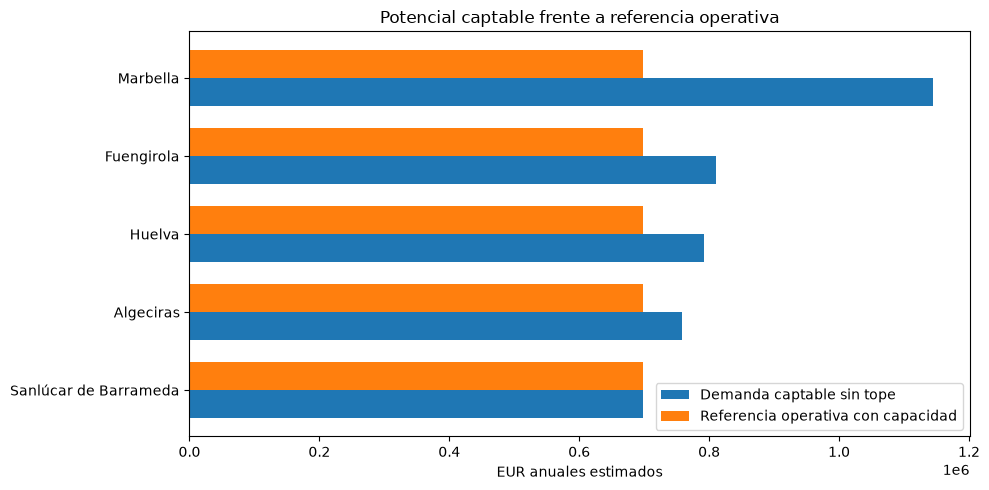

In [15]:
grafico_modelo = modelo.copy().sort_values("facturacion_sin_tope_capacidad")
if not grafico_modelo.empty:
    y = np.arange(len(grafico_modelo))
    plt.figure(figsize=(10, 5))
    plt.barh(y - 0.18, grafico_modelo["facturacion_sin_tope_capacidad"], height=0.36, label="Demanda captable sin tope")
    plt.barh(y + 0.18, grafico_modelo["facturacion_anual"], height=0.36, label="Referencia operativa con capacidad")
    plt.yticks(y, grafico_modelo["municipality_name"])
    plt.xlabel("EUR anuales estimados")
    plt.title("Potencial captable frente a referencia operativa")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 14. Sensibilidad y robustez

### Sensibilidad

La sensibilidad comprueba si la recomendación cambia cuando modificamos supuestos inciertos. Se prueban:

- 3 niveles de penetración: bajo, central y alto.
- 3 niveles de cuota máxima.
- 3 niveles de atractivo del nuevo centro.
- 2 juegos de pesos de competencia: central y solo gimnasios.
- 2 reglas de captación.

```text
3 × 3 × 3 × 2 × 2 = 108 combinaciones
```

El escenario extremo `todo_igual` queda excluido.

### Robustez

La robustez de un municipio es el número de combinaciones en las que aparece entre los seleccionados.

Ejemplo:

```text
Huelva: 82 de 108
```

Significa que Huelva fue seleccionada en 82 combinaciones. **No significa una probabilidad del 75,9 % de éxito**, porque las combinaciones no tienen probabilidades asignadas.

Cómo leer la tabla:

- **Apariciones**: número de combinaciones en las que el municipio fue seleccionado.
- **Posición media cuando aparece**: puesto medio ocupado solo en esas combinaciones.
- **Facturación mínima cuando aparece**: estimación más conservadora entre las combinaciones donde sí fue seleccionado.
- **Calidad central**: estado de calidad calculado con los pesos del escenario central, no con un escenario variable de sensibilidad.

In [16]:
sensibilidad_detalle, sensibilidad_frecuencias = valor_negocio.sensibilidad(datos)

# Añadimos al resumen el estado de calidad fijo del escenario central.
calidad_central = evaluacion[["municipality_code", "quality_status"]].rename(
    columns={"quality_status": "quality_status_central"}
)
robustez = sensibilidad_frecuencias.merge(
    calidad_central, on="municipality_code", how="left", validate="one_to_one"
)

tabla_robustez = robustez[[
    "municipality_name", "apariciones", "posicion_media", "fact_min",
    "robustez", "quality_status_central",
]].head(10).rename(columns={
    "municipality_name": "Municipio",
    "apariciones": "Apariciones",
    "posicion_media": "Posición media cuando aparece",
    "fact_min": "Facturación mínima cuando aparece (EUR)",
    "robustez": "Robustez",
    "quality_status_central": "Calidad en el escenario central",
})
display(tabla_robustez)
print(f"Combinaciones evaluadas: {robustez['combinaciones_totales'].max()}")

,Municipio,Apariciones,Posición media cuando aparece,Facturación mínima cuando aparece (EUR),Robustez,Calidad en el escenario central
0,Huelva,67,2.03,"581,908.47",67 de 108,Supera el control de calidad de competencia po...
1,Dos Hermanas,58,3.29,"564,350.36",58 de 108,Supera el control de calidad de competencia po...
2,Algeciras,55,3.58,"560,083.79",55 de 108,Supera el control de calidad de competencia po...
3,Marbella,48,1.31,"614,442.20",48 de 108,Supera el control de calidad de competencia po...
4,Almería,40,4.10,"654,989.09",40 de 108,Supera el control de calidad de competencia po...
5,Jerez de la Frontera,37,3.30,"621,407.01",37 de 108,Supera el control de calidad de competencia po...
6,Sanlúcar de Barrameda,30,4.13,"582,234.19",30 de 108,Supera el control de calidad de competencia po...
7,Sevilla,27,1.00,"697,944.00",27 de 108,Supera el control de calidad de competencia po...
8,Córdoba,27,2.67,"654,094.39",27 de 108,Supera el control de calidad de competencia po...
9,Fuengirola,21,2.62,"613,718.27",21 de 108,Supera el control de calidad de competencia po...


Combinaciones evaluadas: 108


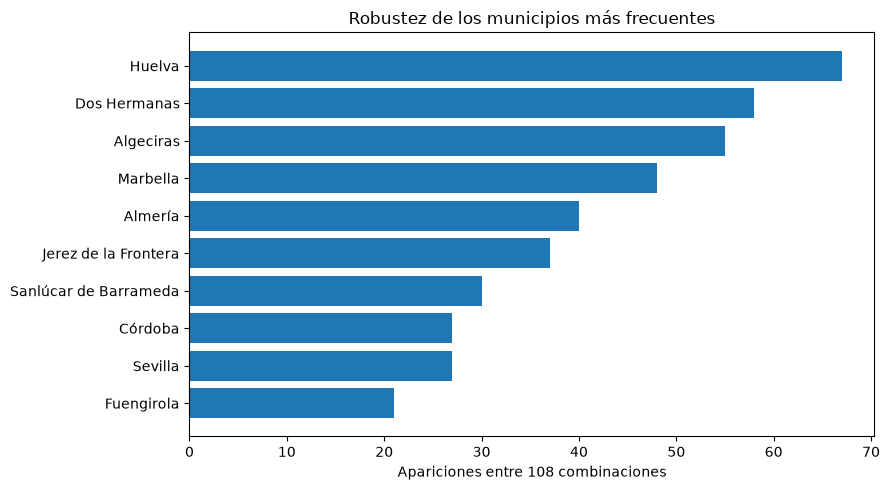

In [17]:
grafico_robustez = robustez.head(10).sort_values("apariciones")
plt.figure(figsize=(9, 5))
plt.barh(grafico_robustez["municipality_name"], grafico_robustez["apariciones"])
plt.xlabel("Apariciones entre 108 combinaciones")
plt.title("Robustez de los municipios más frecuentes")
plt.tight_layout()
plt.show()

## 15. Validación final

El recorrido paso a paso debe coincidir con la evaluación compuesta oficial. También se comprueba que:

- el Modelo tiene como máximo cinco municipios;
- no existen duplicados;
- todos son candidatos, viables y superan calidad;
- la sensibilidad contiene 108 combinaciones;
- no se utiliza `todo_igual`.

In [18]:
evaluacion_oficial = valor_negocio.evaluar(
    datos,
    escenario="central",
    pesos=PESOS_CENTRAL,
    regla="C",
    con_candidatos=True,
)
pd.testing.assert_frame_equal(evaluacion, evaluacion_oficial)

assert len(modelo) <= 5
assert modelo["municipality_code"].is_unique
assert (
    modelo["candidate_flag"]
    & modelo["viable"]
    & modelo["quality_flag"]
).all()
assert sensibilidad_frecuencias["combinaciones_totales"].eq(108).all()
assert not sensibilidad_detalle["escenario"].str.contains("todo_igual", na=False).any()

print("Validaciones del notebook: OK")

Validaciones del notebook: OK


## 16. Conclusión y lectura de negocio

La recomendación final debe interpretarse así:

- El **baseline** representa la práctica simple de seleccionar por tamaño de mercado.
- El **Modelo** añade competencia relativa, viabilidad y calidad mínima del dato.
- Las oportunidades con calidad insuficiente no se borran; quedan pendientes de comprobar con una segunda fuente.
- El **Modelo diversificado** solo puede representar clusters que contengan candidatos simultáneamente viables y con calidad suficiente.
- La facturación anual sin tope permite diferenciar la demanda captable. La cifra de 697.944 € es únicamente la referencia operativa para un centro estándar de 2.600 socios.
- Antes de invertir deben validarse competencia real, ubicación concreta, costes locales, CAPEX y ritmo de maduración del centro.

Para generar todos los CSV y `tablas_definitivas_negocio.md` sin abrir el notebook:

```powershell
python -m src.negocio.ejecutar
```

In [19]:
recomendados = ", ".join(modelo["municipality_name"].tolist()) or "ninguno"
descartados = ", ".join(
    pendientes_calidad.loc[
        pendientes_calidad["motivo_calidad"].str.startswith("Sustituido", na=False),
        "municipality_name",
    ].tolist()
) or "ninguno"

print(f"Municipios recomendados por el Modelo: {recomendados}")
print(f"Municipios sustituidos por calidad: {descartados}")
print(
    f"El Modelo selecciona {int(modelo['viable'].sum())} municipios viables de {len(modelo)}, "
    f"frente a {int(baseline['viable'].sum())} viables de {len(baseline)} en el baseline."
)
print(
    f"Clusters representados: Modelo={modelo['cluster'].nunique()}, "
    f"diversificado={diversificada['cluster'].nunique() if not diversificada.empty else 0}."
)

Municipios recomendados por el Modelo: Marbella, Fuengirola, Huelva, Algeciras, Sanlúcar de Barrameda
Municipios sustituidos por calidad: Puerto de Santa María, El, Alcalá de Guadaíra
El Modelo selecciona 5 municipios viables de 5, frente a 3 viables de 5 en el baseline.
Clusters representados: Modelo=2, diversificado=2.


## 17. Publicación de resultados de negocio

Las tablas y el informe se guardan según `SAVE_LOCALLY` y `SAVE_S3`:

- **Local:** `data/outputs/`.
- **S3:** `results/negocio/`.

Se publican los CSV de detalle y `tablas_definitivas_negocio.md`. Si en S3 quedan `resumen_negocio.md` o `top_facturacion_central.csv` de versiones anteriores, se eliminan.

In [20]:
selecciones_exportacion = {
    "baseline": baseline,
    "modelo": modelo,
    "diversificada": diversificada,
    "pendientes_calidad": pendientes_calidad,
}
comparacion_exportacion = ejecutar.crear_comparacion_estrategias(selecciones_exportacion)

informe_negocio = ejecutar.crear_tablas_definitivas_md(
    selecciones=selecciones_exportacion,
    comparacion=comparacion_exportacion,
    evaluacion=evaluacion,
    frecuencias=robustez,
    sustituciones_calidad=sustituciones_calidad,
    parametros_centrales=p,
)

archivos_negocio = ejecutar.construir_archivos_salida(
    selecciones_exportacion,
    ranking_modelo_completo,
    sustituciones_calidad,
    comparacion_exportacion,
    evaluacion,
    sensibilidad_detalle,
    robustez,
)

salidas_negocio = ejecutar.guardar_salidas_negocio(archivos_negocio, informe_negocio)
obsoletos_s3 = ejecutar.limpiar_salidas_obsoletas_s3()

print("Resultados de negocio guardados:")
for nombre, destino in salidas_negocio.items():
    print(f"- {nombre}: {destino}")
if obsoletos_s3:
    print("Eliminados de S3 por obsoletos:", ", ".join(obsoletos_s3))

Salidas T5 anteriores reemplazadas: baseline_central.csv, comparacion_estrategias_central.csv, modelo_pendiente_validacion.csv, municipios_evaluados_central.csv, ranking_modelo_completo.csv, seleccion_diversificada_clusters_central.csv, seleccion_modelo_central.csv, sensibilidad_detalle.csv, sensibilidad_frecuencias.csv, sustituciones_por_calidad.csv, tablas_definitivas_negocio.md
Resultados de negocio guardados:
- baseline_central.csv: C:\Users\d.gonzalez.fuentes\OneDrive - Accenture\Documents\market-expansion-sot-main\data\outputs\baseline_central.csv
- seleccion_modelo_central.csv: C:\Users\d.gonzalez.fuentes\OneDrive - Accenture\Documents\market-expansion-sot-main\data\outputs\seleccion_modelo_central.csv
- modelo_pendiente_validacion.csv: C:\Users\d.gonzalez.fuentes\OneDrive - Accenture\Documents\market-expansion-sot-main\data\outputs\modelo_pendiente_validacion.csv
- ranking_modelo_completo.csv: C:\Users\d.gonzalez.fuentes\OneDrive - Accenture\Documents\market-expansion-sot-main\